# kino.io.manga: reading MaNGIA (TNG50 mock MaNGA) cubes

**Scope note -- read before trusting anything quantitative here.** MaNGIA
(Sarmiento et al. 2022) is a set of ~10,000 mock MaNGA IFU cubes built from
the TNG50 cosmological simulation (`TEST_DATA.md` Tier B). Its premade
cubes live on the IllustrisTNG data portal, gated behind free user
registration and a personal API key -- there is no public mirror. This
notebook was built in a session with **no such key**, so Section 1 builds a
*synthetic* stand-in cube instead: a known galaxy, rendered through KINO's
own already-tested `kino.instruments.ifu.IFU`, then repackaged into the
exact FITS layout `kino.io.manga.read_mangia_cube` expects (Primary HDU +
`ERROR`/`MASK`/`WAVE` extensions). That reader's own module docstring
documents exactly which conventions (wavelength axis, spaxel scale, flux
unit, mask polarity) are read from a file vs. assumed defaults, and flags
them **unverified** against a real MaNGIA file -- rendering our own cube
sidesteps needing one to check the *reader* actually parses that structure
correctly, but doesn't verify a real file matches it.

**To use this with real data:** register at
https://www.tng-project.org/users/register/, grab your API key from your
account settings, fill in `kino.io.download.MANGIA_FIXTURES[...]["url"]`
(and `["sha256"]`, once you know it) for the galaxies you want, then
`kino.io.download.fetch("mangia_regular_faceon", api_key=YOUR_KEY)` and
pass the returned path to `read_mangia_cube` -- same code path this
notebook exercises below. Section 4 shows the intended call and its
current (expected) failure mode.

## 0. Setup

In [1]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.constants import c as C_LIGHT
from astropy.io import fits

import kino
from kino.analysis.moments import compute_moment_maps
from kino.galaxy import DiscGalaxy
from kino.instruments import IFU
from kino.io.manga import read_mangia_cube
from kino.lensing import apply_shear

rng = np.random.default_rng(seed=7)  # explicit, seeded RNG -- see CLAUDE.md conventions
print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. Render a known galaxy, repackage it as a MaNGIA-shaped cube

A moderately inclined rotating disc (`kino.galaxy.DiscGalaxy`, no shear
applied here -- this notebook is about the *reader*, not lensing),
rendered through the same GMTIFS-like `IFU` config
`05_ifu_instrument_demo.ipynb` uses, cropped to a spectral window a few
times wider than the line's actual extent (see the "window width matters"
caveat in `kino.analysis.moments`'s module docstring -- too wide a window
makes the noise-fragile second moment below unusable). Two renders: a
noiseless one (`rng=None`) for the main correctness demo in Sections 2-3,
and a noisy one for the caveat discussion at the end of Section 3.

In [2]:
gal = DiscGalaxy(r_e=0.3, inc=45.0, pa=30.0, v_flat=150.0, r_t=0.2, z=0.68, sigma0=20.0, flux=1.0)
scene = apply_shear(gal, g1=0.0, g2=0.0)

line_wavelength_rest = 0.6563 * u.um  # Halpha, rest frame

ifu = IFU.from_config(Path("..") / "kino" / "config" / "gmtifs.yaml")
ifu.nx, ifu.ny = 25, 25  # MaNGA-scale field of view at this pixel_scale
ifu.wavelength_min, ifu.wavelength_max, ifu.n_wave = 1.096 * u.um, 1.104 * u.um, 160

line_flux = 4e-16 * u.erg / u.s / u.cm**2
cube_noiseless = ifu.observe(
    scene, line_flux=line_flux, line_wavelength=line_wavelength_rest, rng=None
)
cube_noisy = ifu.observe(scene, line_flux=line_flux, line_wavelength=line_wavelength_rest, rng=rng)
observed_frame = line_wavelength_rest * (1 + gal.z)
window = f"{ifu.wavelength_min}-{ifu.wavelength_max}"
print(f"observed-frame line centre: {observed_frame:.4f}, window {window}")

observed-frame line centre: 1.1026 um, window 1.096 um-1.104 um


In [3]:
def write_mangia_fits(cube, path, redshift):
    flux = cube.flux.astype(np.float32)
    error = np.sqrt(cube.variance).astype(np.float32)
    wavelength = cube.spectral_axis.to_value(u.AA)

    # mark low-significance spaxels invalid, like a real DRP mask would --
    # subtract the flat sky/dark pedestal first, or every spaxel looks
    # equally "bright" (the pedestal dominates the raw per-spaxel total).
    background = np.median(cube.flux, axis=0)
    excess = cube.flux.sum(axis=0) - background * cube.flux.shape[0]
    faint = excess < 0.2 * excess.max()
    valid = np.ones_like(flux, dtype=np.int16)
    valid[:, faint] = 0

    primary = fits.PrimaryHDU(data=flux)
    primary.header["REDSHIFT"] = redshift
    hdus = [
        primary,
        fits.ImageHDU(data=error, name="ERROR"),
        fits.ImageHDU(data=valid, name="MASK"),
        fits.ImageHDU(data=wavelength.astype(np.float64), name="WAVE"),
    ]
    fits.HDUList(hdus).writeto(path, overwrite=True)


data_dir = Path("..") / "data"
data_dir.mkdir(parents=True, exist_ok=True)
noiseless_path = data_dir / "mangia_synthetic_demo.fits.gz"
noisy_path = data_dir / "mangia_synthetic_demo_noisy.fits.gz"
write_mangia_fits(cube_noiseless, noiseless_path, redshift=gal.z)
write_mangia_fits(cube_noisy, noisy_path, redshift=gal.z)
print(
    f"wrote {noiseless_path} and {noisy_path}, {noiseless_path.stat().st_size / 1024:.1f} KB each"
)

wrote ../data/mangia_synthetic_demo.fits.gz and ../data/mangia_synthetic_demo_noisy.fits.gz, 68.3 KB each


## 2. Read it back through `kino.io.manga`

Exactly the function a real downloaded cube would go through -- this is
what's actually being exercised here: the FITS -> `Datacube` conversion,
unit handling, and mask-polarity inversion, not the toy galaxy physics
above.

In [4]:
cube = read_mangia_cube(noiseless_path, pixel_scale=ifu.pixel_scale)
print("shape (n_spec, n_y, n_x):", cube.shape)
print("pixel_scale:", cube.pixel_scale)
print("flux_unit:", cube.flux_unit)
print("redshift:", cube.redshift)
print("unverified:", cube.meta["unverified"])

shape (n_spec, n_y, n_x): (160, 25, 25)
pixel_scale: 0.05 arcsec
flux_unit: 1e-17 erg / (Angstrom s cm2)
redshift: 0.68
unverified: True


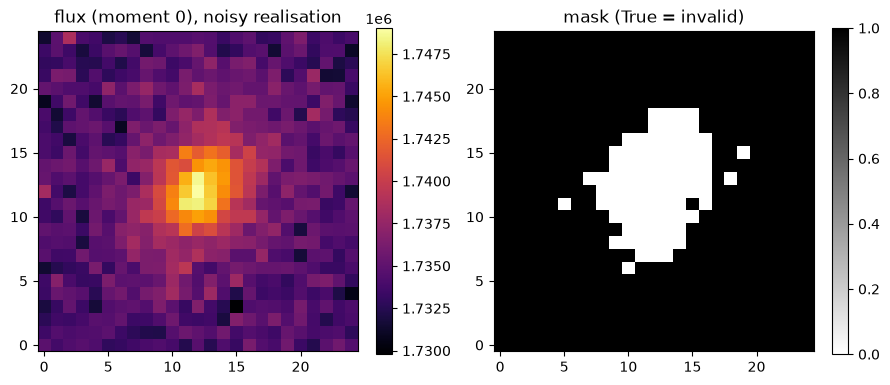

In [5]:
cube_for_image = read_mangia_cube(noisy_path, pixel_scale=ifu.pixel_scale)
flux_map = cube_for_image.flux.sum(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
im0 = axes[0].imshow(flux_map, origin="lower", cmap="inferno")
axes[0].set_title("flux (moment 0), noisy realisation")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(cube_for_image.mask.any(axis=0), origin="lower", cmap="gray_r")
axes[1].set_title("mask (True = invalid)")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()

## 3. Moment maps via `kino.analysis.moments`

The same `compute_moment_maps` used on IFU-rendered cubes directly in
`05_ifu_instrument_demo.ipynb` works here unchanged -- it only depends on
`Datacube`, not on which instrument (or reader) produced it. `lsf_sigma`
removes the known instrumental broadening; the small remaining excess over
the injected `sigma0` is real PSF-driven beam smearing (see
`05_ifu_instrument_demo.ipynb` and `CLAUDE.md`), not an error.

37 unmasked spaxels
Vlos residual (recovered - injected): mean=-2.19, std=1.70 km/s
dispersion, recovered median=22.6 km/s, injected sigma0=20.0 km/s (excess is beam smearing)


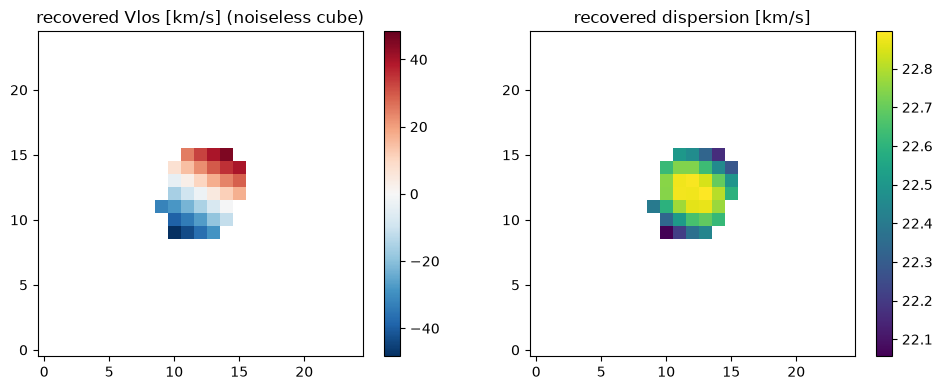

In [6]:
observed_wavelength = line_wavelength_rest * (1 + gal.z)
lsf_sigma_kms = (C_LIGHT * ifu.lsf.sigma(observed_wavelength) / observed_wavelength).to(u.km / u.s)

moments = compute_moment_maps(
    cube, line_wavelength=line_wavelength_rest, snr_threshold=5.0, lsf_sigma=lsf_sigma_kms
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vmax = np.nanmax(np.abs(moments.vlos))
im0 = axes[0].imshow(moments.vlos, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_title("recovered Vlos [km/s] (noiseless cube)")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(moments.dispersion, origin="lower", cmap="viridis")
axes[1].set_title("recovered dispersion [km/s]")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()

nx, ny = ifu.nx, ifu.ny
x = (np.arange(nx) - (nx - 1) / 2) * ifu.pixel_scale.to_value(u.arcsec)
y = (np.arange(ny) - (ny - 1) / 2) * ifu.pixel_scale.to_value(u.arcsec)
xx, yy = np.meshgrid(x, y)
true_vlos = gal.vlos(xx, yy)
true_sigma = gal.velocity_dispersion(xx, yy)

unmasked = ~moments.mask
vlos_resid = (moments.vlos - true_vlos)[unmasked]
print(f"{unmasked.sum()} unmasked spaxels")
vlos_mean, vlos_std = np.nanmean(vlos_resid), np.nanstd(vlos_resid)
print(f"Vlos residual (recovered - injected): mean={vlos_mean:.2f}, std={vlos_std:.2f} km/s")
print(
    f"dispersion, recovered median={np.nanmedian(moments.dispersion[unmasked]):.1f} km/s, "
    f"injected sigma0={gal.sigma0:.1f} km/s (excess is beam smearing)"
)

### Caveat in action: the same setup, with noise

Same galaxy, same instrument config, same window -- just a noisy
realisation instead of the noiseless expected-count cube. Watch how many
spaxels have `dispersion` collapse to exactly 0 (clipped there by
`compute_moment_maps`, see its module docstring's "window width matters"
section): the flux-weighted second moment is far more noise-fragile than
`flux` or `vlos`, even at a spaxel-by-spaxel S/N that would look
perfectly usable for the other two.

In [7]:
moments_noisy = compute_moment_maps(
    cube_for_image, line_wavelength=line_wavelength_rest, snr_threshold=5.0, lsf_sigma=lsf_sigma_kms
)
unmasked_noisy = ~moments_noisy.mask
n_zero = (moments_noisy.dispersion[unmasked_noisy] == 0).sum()
print(
    f"noisy cube: {unmasked_noisy.sum()} unmasked spaxels, "
    f"{n_zero} ({n_zero / unmasked_noisy.sum():.0%}) have dispersion collapsed to 0"
)
print("-> tighten the window, raise the S/N, or use a real line-fitting method instead of moments.")

noisy cube: 25 unmasked spaxels, 20 (80%) have dispersion collapsed to 0
-> tighten the window, raise the S/N, or use a real line-fitting method instead of moments.


## 4. The real-data path (expected to fail today)

With a filled-in `kino.io.download.MANGIA_FIXTURES` entry and a real API
key, this is the call that replaces Section 1 entirely: fetch a real
MaNGIA cube instead of synthesising one, then read it with the exact same
`read_mangia_cube`. Today every fixture's `url` is still `None` (see
`kino/io/download.py`'s module docstring), so this raises
`NotImplementedError` -- shown here deliberately, the same way
`00_kinms_datacube_demo.ipynb` section 5 demonstrates `Datacube`'s own
input validation.

In [8]:
from kino.io.download import fetch

try:
    real_path = fetch("mangia_regular_faceon", api_key="YOUR_TNG_API_KEY_HERE")
    real_cube = read_mangia_cube(real_path)
except NotImplementedError as exc:
    print(f"expected today: {exc}")

expected today: fixture 'mangia_regular_faceon' has no confirmed download URL yet. MaNGIA cubes require a TNG-project API key to browse (https://www.tng-project.org/users/register/); populate MANGIA_FIXTURES[...]['url'] and ['sha256'] once you have access, or call fetch_file() directly with a URL/checksum you already have.


## What's next

- Register for a TNG-project API key, fill in `kino.io.download.MANGIA_FIXTURES`
  with real subhalo IDs and confirmed URLs/checksums for a clean rotator, an
  inclined rotator, and an interacting/tidal galaxy (`TEST_DATA.md` Section 4),
  and re-run Sections 1-3 of this notebook against the *real* cubes instead
  of the synthetic ones -- the reader and moment-map code already work
  unchanged; only the file changes.
- Once real cubes are in hand, verify (and fix as needed) every assumption
  flagged in `kino/io/manga.py`'s module docstring -- wavelength axis
  construction, spaxel scale, flux unit, mask polarity -- against the
  actual FITS headers, per `TEST_DATA.md`'s "verify against the file" rule.
- `kino.analysis.model_compare` (`TEST_DATA.md` Section 3): rank a lensed,
  unlensed, and tidally-disturbed model by evidence on a real MaNGIA cube
  -- the actual point of fetching an interacting/tidal galaxy fixture.
- Real MaNGA (SDSS DR17) cubes share the same LOGCUBE/DAP FITS family
  (`TEST_DATA.md` Tier C) and are public without TNG-specific credentials;
  `read_mangia_cube` may need small adjustments once tried against one.